In [1]:
import sys

print("Hello from the kernel")
print(sys.executable)

Hello from the kernel
d:\BrainTumorHybrid\venv\Scripts\python.exe


In [2]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.12.1+cu126
CUDA available: True
GPU: NVIDIA GeForce GTX 1650


In [3]:
from pathlib import Path

# Project root
PROJECT_ROOT = Path(r"D:\BrainTumorHybrid")

# Dataset location
DATASET_ROOT = PROJECT_ROOT / "dataset" / "raw"

print("Project root:")
print(PROJECT_ROOT)

print("\nDataset root:")
print(DATASET_ROOT)

print("\nDataset exists:", DATASET_ROOT.exists())

Project root:
D:\BrainTumorHybrid

Dataset root:
D:\BrainTumorHybrid\dataset\raw

Dataset exists: True


In [4]:
from pathlib import Path

# Show the first level of the dataset
items = list(DATASET_ROOT.iterdir())

print(f"Found {len(items)} items\n")

for item in items[:30]:
    if item.is_dir():
        print("[DIR] ", item.name)
    else:
        print("[FILE]", item.name)

Found 2 items

[DIR]  ASNR-MICCAI-BraTS2023-GLI-Challenge-TrainingData
[FILE] BraTS2023_2017_GLI_Mapping.xlsx


In [5]:
# Look for common medical imaging files
extensions = {".nii", ".nii.gz"}

nii_files = []

for path in DATASET_ROOT.rglob("*"):
    name = path.name.lower()

    if name.endswith(".nii") or name.endswith(".nii.gz"):
        nii_files.append(path)

print(f"Found {len(nii_files)} NIfTI files.\n")

for path in nii_files[:20]:
    print(path)

Found 6255 NIfTI files.

D:\BrainTumorHybrid\dataset\raw\ASNR-MICCAI-BraTS2023-GLI-Challenge-TrainingData\BraTS-GLI-00000-000\BraTS-GLI-00000-000-seg.nii.gz
D:\BrainTumorHybrid\dataset\raw\ASNR-MICCAI-BraTS2023-GLI-Challenge-TrainingData\BraTS-GLI-00000-000\BraTS-GLI-00000-000-t1c.nii.gz
D:\BrainTumorHybrid\dataset\raw\ASNR-MICCAI-BraTS2023-GLI-Challenge-TrainingData\BraTS-GLI-00000-000\BraTS-GLI-00000-000-t1n.nii.gz
D:\BrainTumorHybrid\dataset\raw\ASNR-MICCAI-BraTS2023-GLI-Challenge-TrainingData\BraTS-GLI-00000-000\BraTS-GLI-00000-000-t2f.nii.gz
D:\BrainTumorHybrid\dataset\raw\ASNR-MICCAI-BraTS2023-GLI-Challenge-TrainingData\BraTS-GLI-00000-000\BraTS-GLI-00000-000-t2w.nii.gz
D:\BrainTumorHybrid\dataset\raw\ASNR-MICCAI-BraTS2023-GLI-Challenge-TrainingData\BraTS-GLI-00002-000\BraTS-GLI-00002-000-seg.nii.gz
D:\BrainTumorHybrid\dataset\raw\ASNR-MICCAI-BraTS2023-GLI-Challenge-TrainingData\BraTS-GLI-00002-000\BraTS-GLI-00002-000-t1c.nii.gz
D:\BrainTumorHybrid\dataset\raw\ASNR-MICCAI-BraTS20

In [6]:
from collections import Counter

# Display file-name patterns
file_names = [p.name for p in nii_files]

print("Example filenames:\n")

for name in file_names[:30]:
    print(name)

Example filenames:

BraTS-GLI-00000-000-seg.nii.gz
BraTS-GLI-00000-000-t1c.nii.gz
BraTS-GLI-00000-000-t1n.nii.gz
BraTS-GLI-00000-000-t2f.nii.gz
BraTS-GLI-00000-000-t2w.nii.gz
BraTS-GLI-00002-000-seg.nii.gz
BraTS-GLI-00002-000-t1c.nii.gz
BraTS-GLI-00002-000-t1n.nii.gz
BraTS-GLI-00002-000-t2f.nii.gz
BraTS-GLI-00002-000-t2w.nii.gz
BraTS-GLI-00003-000-seg.nii.gz
BraTS-GLI-00003-000-t1c.nii.gz
BraTS-GLI-00003-000-t1n.nii.gz
BraTS-GLI-00003-000-t2f.nii.gz
BraTS-GLI-00003-000-t2w.nii.gz
BraTS-GLI-00005-000-seg.nii.gz
BraTS-GLI-00005-000-t1c.nii.gz
BraTS-GLI-00005-000-t1n.nii.gz
BraTS-GLI-00005-000-t2f.nii.gz
BraTS-GLI-00005-000-t2w.nii.gz
BraTS-GLI-00006-000-seg.nii.gz
BraTS-GLI-00006-000-t1c.nii.gz
BraTS-GLI-00006-000-t1n.nii.gz
BraTS-GLI-00006-000-t2f.nii.gz
BraTS-GLI-00006-000-t2w.nii.gz
BraTS-GLI-00008-000-seg.nii.gz
BraTS-GLI-00008-000-t1c.nii.gz
BraTS-GLI-00008-000-t1n.nii.gz
BraTS-GLI-00008-000-t2f.nii.gz
BraTS-GLI-00008-000-t2w.nii.gz


In [7]:
from pathlib import Path
from collections import defaultdict

TRAIN_ROOT = (
    DATASET_ROOT /
    "ASNR-MICCAI-BraTS2023-GLI-Challenge-TrainingData"
)

print("Training data exists:", TRAIN_ROOT.exists())

# Find all NIfTI files
nii_files = [
    p for p in TRAIN_ROOT.rglob("*")
    if p.name.lower().endswith((".nii", ".nii.gz"))
]

# Group files by patient ID
patients = defaultdict(list)

for path in nii_files:
    # Example:
    # BraTS-GLI-00000-000-t1c.nii.gz
    parts = path.name.split("-")

    patient_id = "-".join(parts[:3])

    patients[patient_id].append(path)

print("Total NIfTI files:", len(nii_files))
print("Total patients:", len(patients))

print("\nFirst 10 patients:")

for patient_id in sorted(patients)[:10]:
    print(patient_id, "->", len(patients[patient_id]), "files")

Training data exists: True
Total NIfTI files: 6255
Total patients: 1133

First 10 patients:
BraTS-GLI-00000 -> 5 files
BraTS-GLI-00002 -> 5 files
BraTS-GLI-00003 -> 5 files
BraTS-GLI-00005 -> 5 files
BraTS-GLI-00006 -> 5 files
BraTS-GLI-00008 -> 10 files
BraTS-GLI-00009 -> 10 files
BraTS-GLI-00011 -> 5 files
BraTS-GLI-00012 -> 5 files
BraTS-GLI-00014 -> 10 files


In [8]:
required_modalities = {
    "t1n",
    "t1c",
    "t2w",
    "t2f",
    "seg"
}

complete_patients = []
incomplete_patients = []

for patient_id, files in patients.items():

    found_modalities = set()

    for path in files:
        name = path.name.lower()

        for modality in required_modalities:
            if f"-{modality}.nii" in name:
                found_modalities.add(modality)

    if found_modalities == required_modalities:
        complete_patients.append(patient_id)
    else:
        incomplete_patients.append(
            (patient_id, found_modalities)
        )

print("Complete patients:", len(complete_patients))
print("Incomplete patients:", len(incomplete_patients))

if incomplete_patients:
    print("\nExamples of incomplete patients:")
    for item in incomplete_patients[:10]:
        print(item)

Complete patients: 1133
Incomplete patients: 0


In [9]:
import nibabel as nib
import numpy as np

# Select one patient
patient_id = "BraTS-GLI-00000"

# Find that patient's files
patient_files = patients[patient_id]

print(f"Files for {patient_id}:\n")

for file in patient_files:
    print(file.name)

Files for BraTS-GLI-00000:

BraTS-GLI-00000-000-seg.nii.gz
BraTS-GLI-00000-000-t1c.nii.gz
BraTS-GLI-00000-000-t1n.nii.gz
BraTS-GLI-00000-000-t2f.nii.gz
BraTS-GLI-00000-000-t2w.nii.gz


In [10]:
print(f"\nImage information for {patient_id}:\n")

for file in patient_files:
    img = nib.load(file)

    print(f"{file.name}")
    print(f"  Shape: {img.shape}")
    print(f"  Voxel spacing: {img.header.get_zooms()[:3]}")
    print(f"  Data type: {img.get_data_dtype()}")
    print()


Image information for BraTS-GLI-00000:

BraTS-GLI-00000-000-seg.nii.gz
  Shape: (240, 240, 155)
  Voxel spacing: (np.float32(1.0), np.float32(1.0), np.float32(1.0))
  Data type: float32

BraTS-GLI-00000-000-t1c.nii.gz
  Shape: (240, 240, 155)
  Voxel spacing: (np.float32(1.0), np.float32(1.0), np.float32(1.0))
  Data type: int16

BraTS-GLI-00000-000-t1n.nii.gz
  Shape: (240, 240, 155)
  Voxel spacing: (np.float32(1.0), np.float32(1.0), np.float32(1.0))
  Data type: int16

BraTS-GLI-00000-000-t2f.nii.gz
  Shape: (240, 240, 155)
  Voxel spacing: (np.float32(1.0), np.float32(1.0), np.float32(1.0))
  Data type: int16

BraTS-GLI-00000-000-t2w.nii.gz
  Shape: (240, 240, 155)
  Voxel spacing: (np.float32(1.0), np.float32(1.0), np.float32(1.0))
  Data type: int16



In [11]:
seg_file = next(
    file for file in patient_files
    if "-seg.nii" in file.name.lower()
)

seg_img = nib.load(seg_file)
seg_data = np.asarray(seg_img.dataobj)

print("Segmentation shape:", seg_data.shape)
print("Unique labels:", np.unique(seg_data))

Segmentation shape: (240, 240, 155)
Unique labels: [0. 1. 2. 3.]


In [12]:
labels, counts = np.unique(seg_data, return_counts=True)

print("Segmentation label distribution:\n")

for label, count in zip(labels, counts):
    percentage = (count / seg_data.size) * 100
    print(f"Label {int(label)}: {count:,} voxels ({percentage:.4f}%)")

Segmentation label distribution:

Label 0: 8,870,695 voxels (99.3581%)
Label 1: 11,738 voxels (0.1315%)
Label 2: 12,836 voxels (0.1438%)
Label 3: 32,731 voxels (0.3666%)


In [13]:
import matplotlib.pyplot as plt
import numpy as np
import nibabel as nib

# Load the four MRI modalities
modalities = {}

for modality in ["t1n", "t1c", "t2w", "t2f"]:
    file = next(
        f for f in patient_files
        if f.name.lower().endswith(f"-{modality}.nii.gz")
    )

    modalities[modality] = nib.load(file).get_fdata()

# Load segmentation
seg_file = next(
    f for f in patient_files
    if f.name.lower().endswith("-seg.nii.gz")
)

segmentation = nib.load(seg_file).get_fdata()

print("Loaded modalities:")
for name, volume in modalities.items():
    print(name, volume.shape)

print("Segmentation:", segmentation.shape)

Loaded modalities:
t1n (240, 240, 155)
t1c (240, 240, 155)
t2w (240, 240, 155)
t2f (240, 240, 155)
Segmentation: (240, 240, 155)


In [14]:
tumor_slices = np.where(
    np.any(segmentation > 0, axis=(0, 1))
)[0]

print("Number of tumor-containing slices:", len(tumor_slices))
print("First tumor slice:", tumor_slices[0])
print("Last tumor slice:", tumor_slices[-1])

Number of tumor-containing slices: 47
First tumor slice: 49
Last tumor slice: 95


In [15]:
# Pick the middle tumor-containing slice
slice_idx = tumor_slices[len(tumor_slices) // 2]

print("Selected slice:", slice_idx)

Selected slice: 72


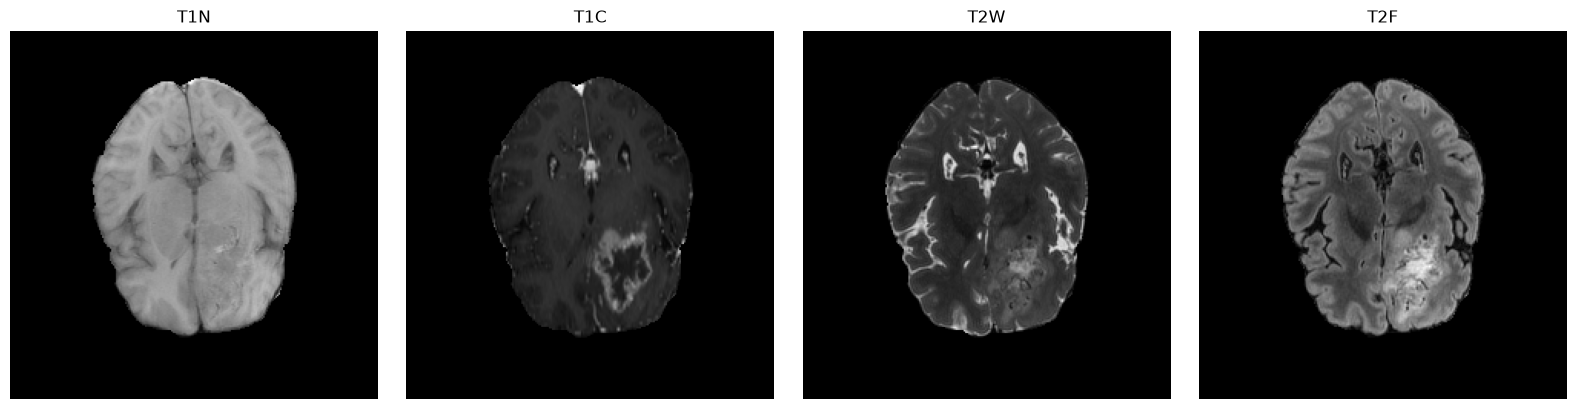

In [16]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))

for ax, (name, volume) in zip(axes, modalities.items()):
    ax.imshow(
        np.rot90(volume[:, :, slice_idx]),
        cmap="gray"
    )
    ax.set_title(name.upper())
    ax.axis("off")

plt.tight_layout()
plt.show()

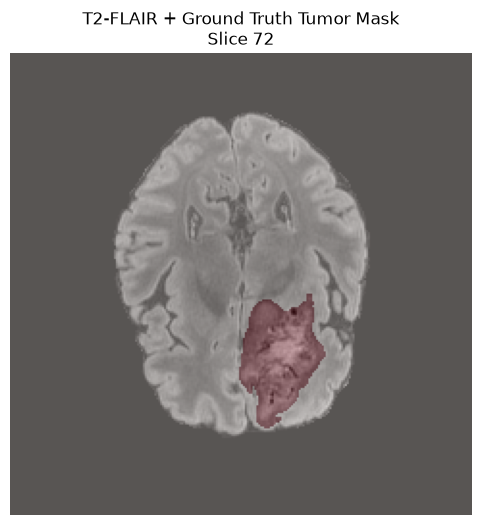

In [17]:
# Create binary tumor mask
binary_mask = segmentation > 0

# Display T2-FLAIR with tumor overlay
plt.figure(figsize=(6, 6))

plt.imshow(
    np.rot90(modalities["t2f"][:, :, slice_idx]),
    cmap="gray"
)

plt.imshow(
    np.rot90(binary_mask[:, :, slice_idx]),
    cmap="Reds",
    alpha=0.35
)

plt.title(f"T2-FLAIR + Ground Truth Tumor Mask\nSlice {slice_idx}")
plt.axis("off")
plt.show()

In [18]:
tumor_slice_count = len(tumor_slices)

print("Total slices per patient:", segmentation.shape[2])
print("Tumor-containing slices:", tumor_slice_count)
print(
    "Percentage containing tumor:",
    f"{100 * tumor_slice_count / segmentation.shape[2]:.2f}%"
)

Total slices per patient: 155
Tumor-containing slices: 47
Percentage containing tumor: 30.32%
